# Baseline comparison: paper LSTM vs our models

This notebook compares our rolling-phase results against the **vanilla LSTM baseline reported in Table 2** of the ESTIMATE paper.

It is designed to live at:

```text
notebook/baseline_comparison.ipynb
```

and read model outputs from:

```text
results/vanilla/phase_summary.csv
results/sector/phase_summary.csv   # optional
```

## Important comparability note

At the moment, **IC** and **Rank_IC** are the cleanest metrics to compare.

Our current implementations of **Return** and **Prec@N** do not yet reproduce the paper's evaluation procedure exactly, so charts for those metrics are included only as **provisional diagnostics**.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebook" else cwd
RESULTS = ROOT / "results"

print("Repository root:", ROOT)
print("Results directory:", RESULTS)


Repository root: c:\Thesis\thesis
Results directory: c:\Thesis\thesis\results


## Paper baseline values

These are the per-phase vanilla-LSTM values from Table 2 of the paper.


In [2]:
paper = pd.DataFrame({
    "phase": np.arange(1, 13),
    "Return": [0.064, 0.057, 0.028, 0.058, 0.036, -0.032, 0.059, -0.139, 0.125, 0.100, 0.062, 0.008],
    "IC": [-0.014, -0.030, -0.016, 0.006, 0.020, -0.034, -0.006, 0.014, -0.002, -0.039, 0.022, -0.023],
    "Rank_IC": [-0.151, -0.356, -0.289, 0.089, 0.186, -1.091, -0.151, 0.201, -0.019, -0.496, 0.259, -0.397],
    "Prec@N": [0.542, 0.553, 0.581, 0.471, 0.456, 0.569, 0.440, 0.547, 0.588, 0.615, 0.554, 0.608],
})

paper_means_reported = pd.Series({
    "Return": 0.036,
    "IC": -0.009,
    "Rank_IC": -0.185,
    "Prec@N": 0.544,
}, name="Paper LSTM")

paper


,phase,Return,IC,Rank_IC,Prec@N
0,1,0.064,-0.014,-0.151,0.542
1,2,0.057,-0.030,-0.356,0.553
2,3,0.028,-0.016,-0.289,0.581
3,4,0.058,0.006,0.089,0.471
4,5,0.036,0.020,0.186,0.456
5,6,-0.032,-0.034,-1.091,0.569
6,7,0.059,-0.006,-0.151,0.440
7,8,-0.139,0.014,0.201,0.547
8,9,0.125,-0.002,-0.019,0.588
9,10,0.100,-0.039,-0.496,0.615


## Load our experiment outputs

Vanilla is required. If sector results exist later, they are added automatically.


In [3]:
def load_phase_summary(model_name):
    path = RESULTS / model_name / "phase_summary.csv"
    if not path.exists():
        raise FileNotFoundError(f"Could not find {path}. Run: python -m src.main --model {model_name}")
    df = pd.read_csv(path).sort_values("phase").reset_index(drop=True)
    if len(df) != 12:
        print(f"Warning: {model_name} has {len(df)} completed phases, not 12.")
    return df

models = {"Our vanilla": load_phase_summary("vanilla")}
sector_path = RESULTS / "sector" / "phase_summary.csv"
if sector_path.exists():
    models["Sector-tagged"] = load_phase_summary("sector")

for name, df in models.items():
    print(f"{name}: {len(df)} phases")
    display(df)


Our vanilla: 12 phases


,Return,IC,ICIR,Rank_IC,Rank_ICIR,Prec@N,MAE,RMSE,phase
0,0.120244,-0.012674,-0.159045,-0.029694,-0.419649,0.571429,0.020319,0.029571,1
1,0.086147,0.026206,0.377414,0.019903,0.250777,0.560870,0.021175,0.031192,2
2,0.258351,0.033237,0.454767,0.034527,0.496552,0.572973,0.027467,0.038162,3
3,-0.064379,0.001494,0.016540,0.013882,0.135263,0.546018,0.024518,0.034203,4
4,0.065496,-0.001531,-0.012935,0.012817,0.091803,0.533929,0.032376,0.044229,5
5,-0.060163,0.006633,0.066540,-0.004613,-0.036943,0.518421,0.027507,0.038630,6
6,0.156151,0.008540,0.139820,-0.003947,-0.055194,0.588393,0.023978,0.034355,7
7,-0.082185,0.025775,0.273695,0.067139,0.396453,0.508850,0.066083,0.097533,8
8,0.186249,0.005901,0.068682,0.005830,0.074661,0.583333,0.035030,0.048848,9
9,0.180102,0.004162,0.029368,-0.000304,-0.001964,0.556637,0.030509,0.041863,10


## 1. IC across all 12 phases

Higher is better. Positive IC means higher predicted returns tend to correspond to higher realized returns cross-sectionally.


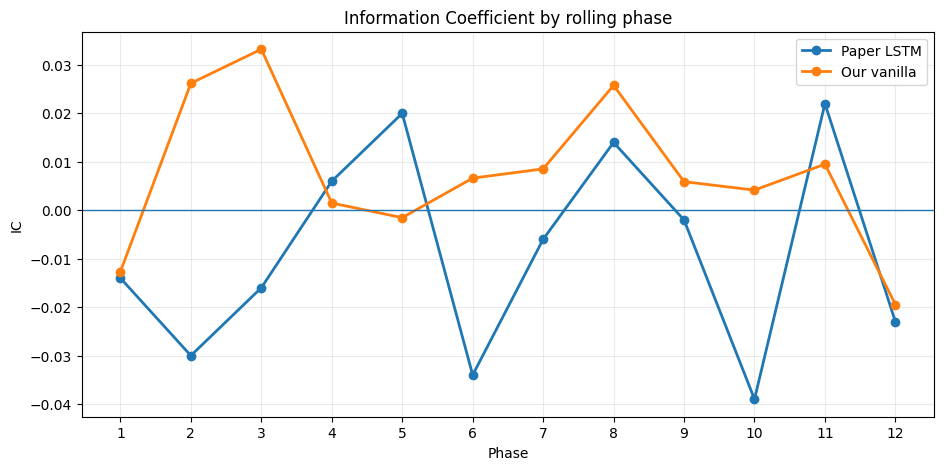

In [4]:
plt.figure(figsize=(11, 5))
plt.plot(paper["phase"], paper["IC"], marker="o", linewidth=2, label="Paper LSTM")
for name, df in models.items():
    plt.plot(df["phase"], df["IC"], marker="o", linewidth=2, label=name)
plt.axhline(0, linewidth=1)
plt.xticks(range(1, 13))
plt.xlabel("Phase")
plt.ylabel("IC")
plt.title("Information Coefficient by rolling phase")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 2. Rank_IC across all 12 phases

Rank_IC uses Spearman correlation and measures how well the model ranks stocks by future return.


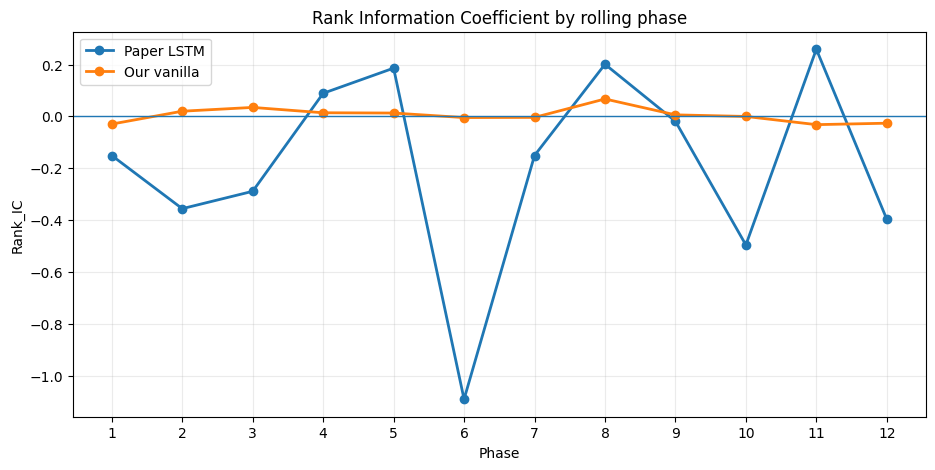

In [5]:
plt.figure(figsize=(11, 5))
plt.plot(paper["phase"], paper["Rank_IC"], marker="o", linewidth=2, label="Paper LSTM")
for name, df in models.items():
    plt.plot(df["phase"], df["Rank_IC"], marker="o", linewidth=2, label=name)
plt.axhline(0, linewidth=1)
plt.xticks(range(1, 13))
plt.xlabel("Phase")
plt.ylabel("Rank_IC")
plt.title("Rank Information Coefficient by rolling phase")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 3. Mean IC and Rank_IC

This is the most compact comparison of the currently comparable metrics.


,IC,Rank_IC
Model,,
Paper LSTM,-0.009000,-0.185000
Our vanilla,0.007316,0.004771


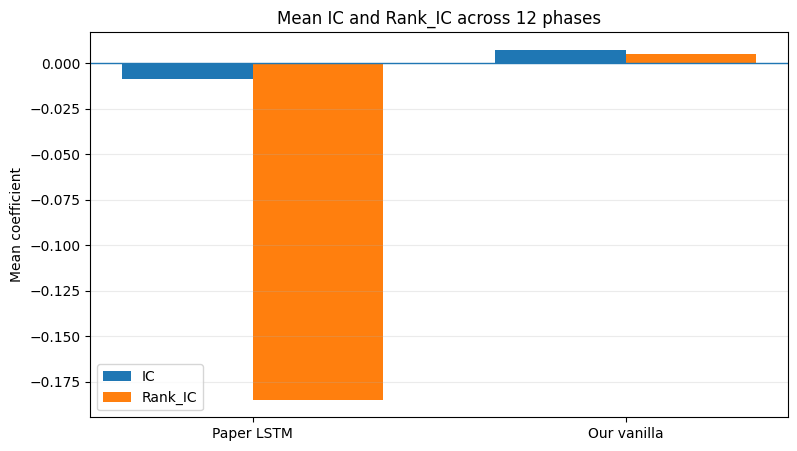

In [6]:
rows = [{"Model":"Paper LSTM","IC":paper_means_reported["IC"],"Rank_IC":paper_means_reported["Rank_IC"]}]
for name, df in models.items():
    rows.append({"Model":name,"IC":df["IC"].mean(),"Rank_IC":df["Rank_IC"].mean()})
mean_compare = pd.DataFrame(rows).set_index("Model")
display(mean_compare)

x = np.arange(len(mean_compare.index))
width = 0.35
plt.figure(figsize=(9, 5))
plt.bar(x - width/2, mean_compare["IC"], width, label="IC")
plt.bar(x + width/2, mean_compare["Rank_IC"], width, label="Rank_IC")
plt.axhline(0, linewidth=1)
plt.xticks(x, mean_compare.index)
plt.ylabel("Mean coefficient")
plt.title("Mean IC and Rank_IC across 12 phases")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.show()


## 4. Per-phase improvement over the paper baseline

A value above zero means our model performed better than the paper LSTM in that phase.


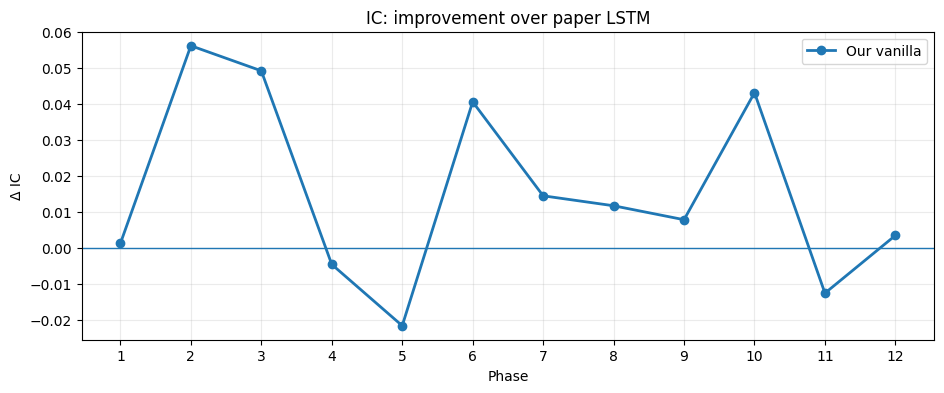

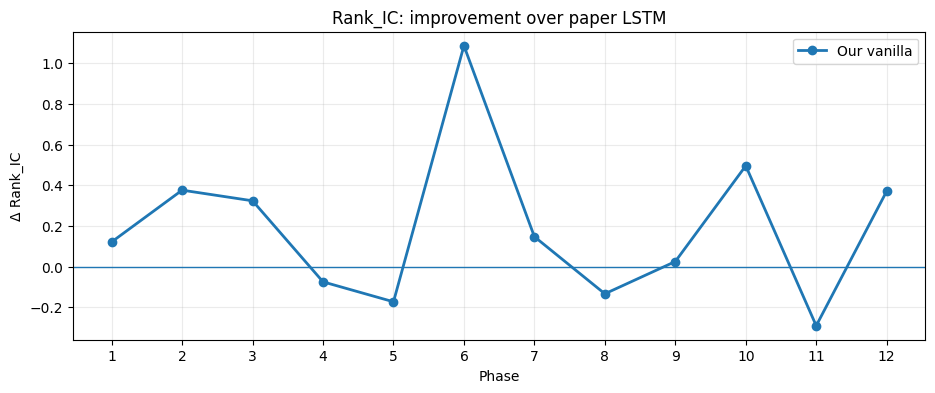

In [7]:
for metric in ["IC", "Rank_IC"]:
    plt.figure(figsize=(11, 4))
    for name, df in models.items():
        merged = paper[["phase", metric]].merge(df[["phase", metric]], on="phase", suffixes=("_paper", "_ours"))
        improvement = merged[f"{metric}_ours"] - merged[f"{metric}_paper"]
        plt.plot(merged["phase"], improvement, marker="o", linewidth=2, label=name)
    plt.axhline(0, linewidth=1)
    plt.xticks(range(1, 13))
    plt.xlabel("Phase")
    plt.ylabel(f"Δ {metric}")
    plt.title(f"{metric}: improvement over paper LSTM")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


## 5. Phase win counts

Counts how often each model beats the paper baseline phase-by-phase. This is descriptive, not a statistical-significance test.


In [8]:
win_rows = []
for name, df in models.items():
    row = {"Model": name}
    for metric in ["IC", "Rank_IC"]:
        merged = paper[["phase", metric]].merge(df[["phase", metric]], on="phase", suffixes=("_paper", "_ours"))
        row[f"{metric} wins"] = int((merged[f"{metric}_ours"] > merged[f"{metric}_paper"]).sum())
    win_rows.append(row)
wins = pd.DataFrame(win_rows).set_index("Model")
display(wins)


,IC wins,Rank_IC wins
Model,,
Our vanilla,9,8


## 6. Provisional Return comparison

**Do not use this chart to claim improvement over the paper yet.** The paper's Return comes from a top-k trading simulator with a 7% trailing stop and a 20% take-profit rule. Our current Return is a simpler placeholder.


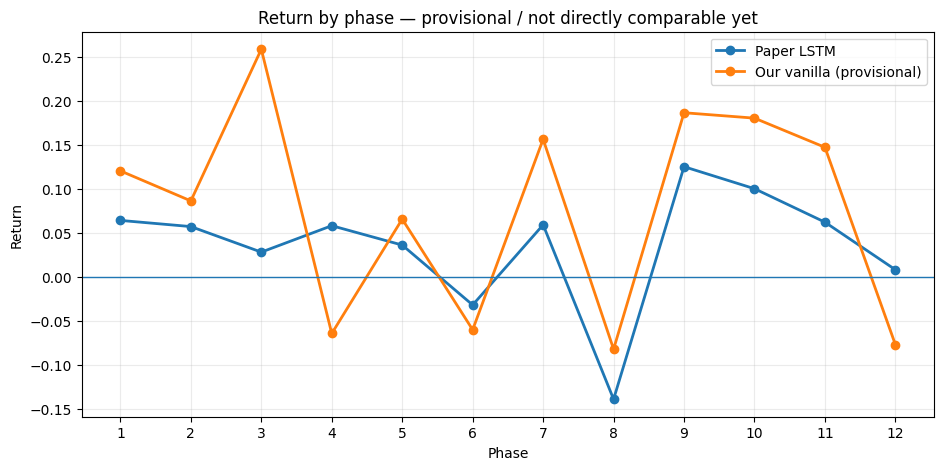

In [9]:
plt.figure(figsize=(11, 5))
plt.plot(paper["phase"], paper["Return"], marker="o", linewidth=2, label="Paper LSTM")
for name, df in models.items():
    plt.plot(df["phase"], df["Return"], marker="o", linewidth=2, label=f"{name} (provisional)")
plt.axhline(0, linewidth=1)
plt.xticks(range(1, 13))
plt.xlabel("Phase")
plt.ylabel("Return")
plt.title("Return by phase — provisional / not directly comparable yet")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 7. Provisional Prec@N comparison

Our current values are around 0.05 while the paper reports roughly 0.5, which indicates an evaluation-definition mismatch that still needs to be resolved.


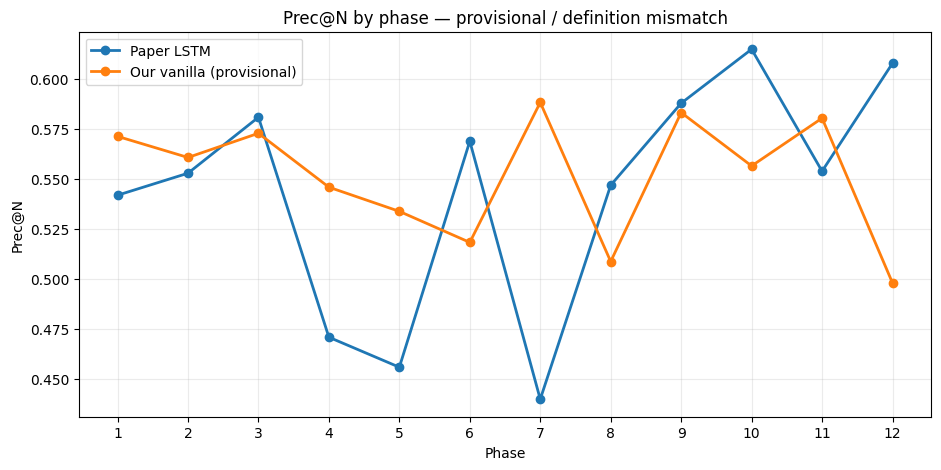

In [10]:
plt.figure(figsize=(11, 5))
plt.plot(paper["phase"], paper["Prec@N"], marker="o", linewidth=2, label="Paper LSTM")
for name, df in models.items():
    plt.plot(df["phase"], df["Prec@N"], marker="o", linewidth=2, label=f"{name} (provisional)")
plt.xticks(range(1, 13))
plt.xlabel("Phase")
plt.ylabel("Prec@N")
plt.title("Prec@N by phase — provisional / definition mismatch")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 8. Summary table


In [11]:
summary_rows = [{
    "Model":"Paper LSTM",
    "Return":paper_means_reported["Return"],
    "IC":paper_means_reported["IC"],
    "Rank_IC":paper_means_reported["Rank_IC"],
    "Prec@N":paper_means_reported["Prec@N"],
    "Return comparable?":"Yes (paper)",
    "Prec@N comparable?":"Yes (paper)",
}]
for name, df in models.items():
    summary_rows.append({
        "Model":name,
        "Return":df["Return"].mean(),
        "IC":df["IC"].mean(),
        "Rank_IC":df["Rank_IC"].mean(),
        "Prec@N":df["Prec@N"].mean(),
        "Return comparable?":"Not yet",
        "Prec@N comparable?":"Not yet",
    })
summary_table = pd.DataFrame(summary_rows).set_index("Model")
display(summary_table)


,Return,IC,Rank_IC,Prec@N,Return comparable?,Prec@N comparable?
Model,,,,,,
Paper LSTM,0.03600,-0.009000,-0.185000,0.544000,Yes (paper),Yes (paper)
Our vanilla,0.07633,0.007316,0.004771,0.551625,Not yet,Not yet


## Summary

The current vanilla LSTM (baseline) using the ESTIMATE's rolling 12-phase evaluation protocol, 20-day historical window, 5-day prediction horizon, relative-return regression target, RMSE objective, and reported evaluation metrics...